# Lab 9 — MLP

**Phần bài tập — Nguyễn Đình Huy — 2474802010140**

Mỗi mục/bài là một cell code. Chạy từ trên xuống; hình được lưu vào `figures/`. Dùng `scripts/run_all.py` để lưu thêm nhật ký TXT vào `outputs/`.

## Bài 1 — Tự dự đoán bằng trọng số đã học

In [1]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(tep_du_lieu("xor.csv"))
X, y = df[["x1", "x2"]], df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
mlp = MLPClassifier(hidden_layer_sizes=(8,), solver="lbfgs", max_iter=5000, random_state=0).fit(X_tr, y_tr)
nam_diem = X_te.iloc[:5].to_numpy()
W1, W2 = mlp.coefs_
b1, b2 = mlp.intercepts_
H = np.maximum(0, nam_diem @ W1 + b1)
z = H @ W2 + b2
# Dạng sigmoid ổn định số học, chỉ dùng NumPy.
xac_suat_tu_tinh = np.exp(-np.logaddexp(0, -z)).ravel()
xac_suat_thu_vien = mlp.predict_proba(X_te.iloc[:5])[:, 1]
bang = X_te.iloc[:5].copy()
bang["tu_tinh"] = xac_suat_tu_tinh
bang["thu_vien"] = xac_suat_thu_vien
bang["sai_lech"] = np.abs(xac_suat_tu_tinh - xac_suat_thu_vien)
print(bang.to_string(float_format=lambda x: f"{x:.12f}"))
print(f"Sai lệch lớn nhất: {bang.sai_lech.max():.3e}")
assert np.allclose(xac_suat_tu_tinh, xac_suat_thu_vien, rtol=1e-12, atol=1e-12)
print("Hai cách khớp: mỗi lớp nhân với ma trận trọng số rồi cộng hệ số chặn; ReLU ở lớp ẩn tạo tính phi tuyến, sigmoid lớp ra đổi logit thành xác suất lớp 1.")


                 x1              x2        tu_tinh       thu_vien       sai_lech
338  0.331900000000 -0.559500000000 0.017557985373 0.017557985373 0.000000000000
342 -0.701600000000 -0.825100000000 0.999434831959 0.999434831959 0.000000000000
40   0.515500000000 -0.005200000000 0.794331056599 0.794331056599 0.000000000000
231 -0.603600000000  0.272600000000 0.134400889648 0.134400889648 0.000000000000
242  0.274800000000  0.351500000000 0.957805718116 0.957805718116 0.000000000000
Sai lệch lớn nhất: 1.110e-16
Hai cách khớp: mỗi lớp nhân với ma trận trọng số rồi cộng hệ số chặn; ReLU ở lớp ẩn tạo tính phi tuyến, sigmoid lớp ra đổi logit thành xác suất lớp 1.


## Bài 2 — Một mạng XOR khác

In [2]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
h1 = np.maximum(0, X[:, 0] - X[:, 1])
h2 = np.maximum(0, X[:, 1] - X[:, 0])
y = h1 + h2
that = np.logical_xor(X[:, 0], X[:, 1]).astype(int)
print(pd.DataFrame({"x1": X[:, 0], "x2": X[:, 1], "h1": h1, "h2": h2, "y": y, "XOR": that}).to_string(index=False))
assert np.array_equal(y, that)
print("Khi hai đầu vào bằng nhau, hai hiệu đều bằng 0 nên đầu ra bằng 0. Khi khác nhau, một hiệu bằng 1 còn hiệu kia bằng -1; ReLU giữ 1 và loại -1 nên tổng bằng 1.")
print("Mạng tính |x1-x2|; trên đầu vào nhị phân, giá trị đó chính là XOR. Với số thực bất kỳ, đầu ra không còn là phép XOR nhị phân.")


 x1  x2  h1  h2   y  XOR
0.0 0.0 0.0 0.0 0.0    0
0.0 1.0 0.0 1.0 1.0    1
1.0 0.0 1.0 0.0 1.0    1
1.0 1.0 0.0 0.0 0.0    0
Khi hai đầu vào bằng nhau, hai hiệu đều bằng 0 nên đầu ra bằng 0. Khi khác nhau, một hiệu bằng 1 còn hiệu kia bằng -1; ReLU giữ 1 và loại -1 nên tổng bằng 1.
Mạng tính |x1-x2|; trên đầu vào nhị phân, giá trị đó chính là XOR. Với số thực bất kỳ, đầu ra không còn là phép XOR nhị phân.


## Bài 3 — So sánh các hàm kích hoạt

            tap_hoc  tap_kiem_tra
activation                       
logistic     0.8400        0.8533
tanh         0.8711        0.9067
relu         0.8844        0.9067
Hàm cho accuracy kiểm tra cao nhất trong phép thử này: tanh, relu (0.9067).
Kết luận chỉ cho bộ dữ liệu và seed này; khi chọn hàm để triển khai cần kiểm định chéo trên tập học, không dùng tập kiểm tra để dò tiếp.


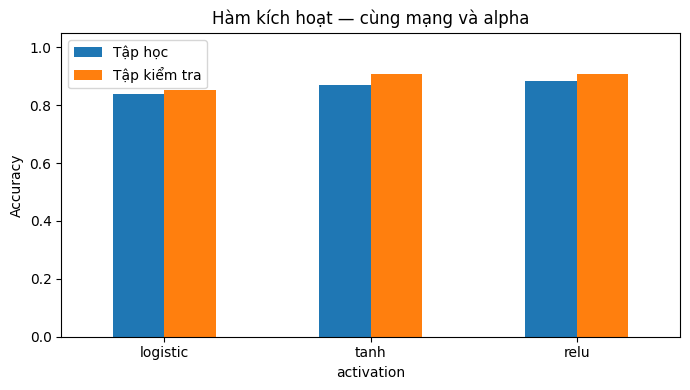

In [3]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X, y = df[["x1", "x2"]], df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
ket_qua = []
for ham in ["logistic", "tanh", "relu"]:
    mang = make_pipeline(StandardScaler(), MLPClassifier(
        hidden_layer_sizes=(100, 100), alpha=1.0, activation=ham,
        solver="lbfgs", max_iter=20000, random_state=0)).fit(X_tr, y_tr)
    ket_qua.append({"activation": ham, "tap_hoc": accuracy_score(y_tr, mang.predict(X_tr)),
                    "tap_kiem_tra": accuracy_score(y_te, mang.predict(X_te))})
bang = pd.DataFrame(ket_qua).set_index("activation")
print(bang.round(4).to_string())
tot = bang.index[np.isclose(bang.tap_kiem_tra, bang.tap_kiem_tra.max())].tolist()
print(f"Hàm cho accuracy kiểm tra cao nhất trong phép thử này: {', '.join(tot)} ({bang.tap_kiem_tra.max():.4f}).")
print("Kết luận chỉ cho bộ dữ liệu và seed này; khi chọn hàm để triển khai cần kiểm định chéo trên tập học, không dùng tập kiểm tra để dò tiếp.")
ax = bang.plot.bar(rot=0, figsize=(7, 4), ylim=(0, 1.05), ylabel="Accuracy", title="Hàm kích hoạt — cùng mạng và alpha")
ax.legend(["Tập học", "Tập kiểm tra"])
plt.tight_layout()
plt.savefig(thu_muc_hinh / "so_sanh_kich_hoat.png", dpi=150)
plt.show()


## Bài 4 — Tốc độ học

 toc_do_hoc  so_vong  loss_cuoi  accuracy
   0.000100      582   0.018928  0.988889
   0.001000      144   0.005210  0.984444
   0.010000       38   0.001077  0.977778
   0.100000       30   0.099601  0.948889
Tốc độ quá nhỏ làm mất mát giảm chậm và cần nhiều vòng; tốc độ quá lớn có thể vượt vùng tốt, làm loss dao động và ảnh hưởng khả năng tổng quát hóa.
Adam điều chỉnh bước học theo từng tham số, nên không có quy tắc mọi tốc độ lớn đều phân kỳ; cần đọc đường loss và accuracy thực tế cùng nhau.


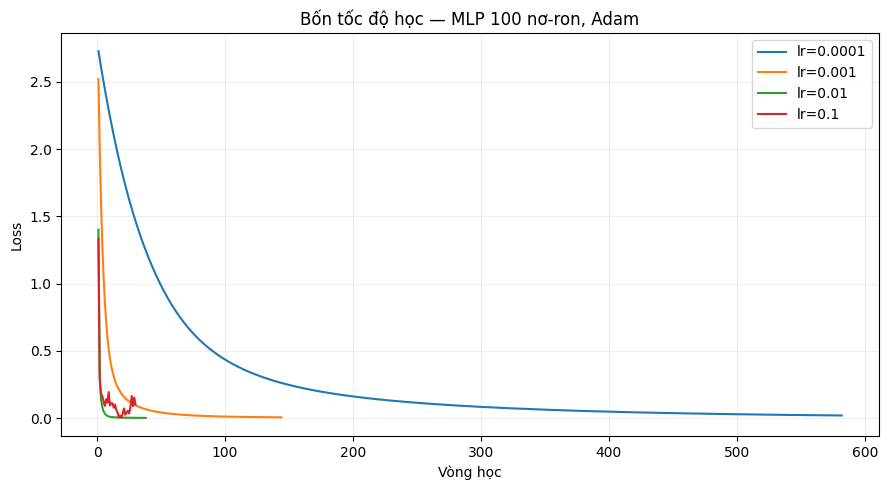

In [4]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.datasets import load_digits
X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
fig, ax = plt.subplots(figsize=(9, 5))
ket_qua = []
for toc_do in [0.0001, 0.001, 0.01, 0.1]:
    mang = make_pipeline(StandardScaler(), MLPClassifier(
        hidden_layer_sizes=(100,), max_iter=1000, random_state=0,
        learning_rate_init=toc_do)).fit(X_tr, y_tr)
    mlp = mang[-1]
    ket_qua.append({"toc_do_hoc": toc_do, "so_vong": mlp.n_iter_, "loss_cuoi": mlp.loss_,
                    "accuracy": accuracy_score(y_te, mang.predict(X_te))})
    ax.plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, label=f"lr={toc_do}")
print(pd.DataFrame(ket_qua).to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("Tốc độ quá nhỏ làm mất mát giảm chậm và cần nhiều vòng; tốc độ quá lớn có thể vượt vùng tốt, làm loss dao động và ảnh hưởng khả năng tổng quát hóa.")
print("Adam điều chỉnh bước học theo từng tham số, nên không có quy tắc mọi tốc độ lớn đều phân kỳ; cần đọc đường loss và accuracy thực tế cùng nhau.")
ax.set(xlabel="Vòng học", ylabel="Loss", title="Bốn tốc độ học — MLP 100 nơ-ron, Adam")
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
plt.savefig(thu_muc_hinh / "toc_do_hoc.png", dpi=150)
plt.show()


## Bài 5 — Dò lưới cho mạng nơ-ron

In [5]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.datasets import load_digits
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)
pipeline = make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, random_state=0))
luoi = {"mlpclassifier__hidden_layer_sizes": [(10,), (50,), (100,), (50, 50)],
        "mlpclassifier__alpha": [0.0001, 0.01, 1.0]}
# Chuẩn hóa nằm trong pipeline: mỗi fold chỉ học scaler từ phần học của fold.
tim = GridSearchCV(pipeline, luoi, scoring="accuracy", cv=5, n_jobs=1, error_score="raise")
tim.fit(X_tr, y_tr)
bang = pd.DataFrame(tim.cv_results_)[["param_mlpclassifier__hidden_layer_sizes", "param_mlpclassifier__alpha", "mean_test_score", "std_test_score", "rank_test_score"]]
bang.columns = ["lop_an", "alpha", "accuracy_cv", "std_cv", "hang"]
print(bang.sort_values("hang").to_string(index=False))
print("\nCặp tốt nhất:", tim.best_params_)
print(f"Accuracy CV tốt nhất: {tim.best_score_:.4f}")
acc_mlp = accuracy_score(y_te, tim.predict(X_te))
# SVM mặc định không chuẩn hóa như bảng đối chiếu mục 6, cùng split.
svm = SVC().fit(X_tr, y_tr)
acc_svm = accuracy_score(y_te, svm.predict(X_te))
print(f"Tập kiểm tra: MLP = {acc_mlp:.4f}; SVM RBF = {acc_svm:.4f}.")
print("MLP " + ("vượt" if acc_mlp > acc_svm else "bằng" if acc_mlp == acc_svm else "chưa vượt") +
      " SVM trên lần chia này. Cặp tham số được chọn bằng CV trên tập học, rồi mới chấm tập kiểm tra.")


  lop_an  alpha  accuracy_cv   std_cv  hang
   (50,) 1.0000     0.978469 0.005461     1
(50, 50) 1.0000     0.977725 0.004075     2
  (100,) 1.0000     0.977723 0.005273     3
  (100,) 0.0001     0.975498 0.008007     4
  (100,) 0.0100     0.975498 0.008007     4
   (50,) 0.0100     0.975498 0.003805     4
   (50,) 0.0001     0.974013 0.004707     7
(50, 50) 0.0100     0.968063 0.010684     8
(50, 50) 0.0001     0.968063 0.010684     8
   (10,) 1.0000     0.965108 0.008640    10
   (10,) 0.0100     0.948757 0.015861    11
   (10,) 0.0001     0.948016 0.016129    12

Cặp tốt nhất: {'mlpclassifier__alpha': 1.0, 'mlpclassifier__hidden_layer_sizes': (50,)}
Accuracy CV tốt nhất: 0.9785
Tập kiểm tra: MLP = 0.9822; SVM RBF = 0.9911.
MLP chưa vượt SVM trên lần chia này. Cặp tham số được chọn bằng CV trên tập học, rồi mới chấm tập kiểm tra.


## Bài 6 — Mạng nơ-ron cho hồi quy

MLP: MAE kiểm tra = 0.500795 tỷ đồng; giá 250 m² = 28.175828 tỷ đồng.
Hồi quy tuyến tính: MAE kiểm tra = 0.257784 tỷ đồng; giá 250 m² = 19.913943 tỷ đồng.
Dữ liệu quan sát chỉ từ 35.5 tới 117.5 m².
Căn 250 m² nằm ngoài dữ liệu; chưa có giá thật để khẳng định mô hình nào ngoại suy chính xác hơn. MLP ReLU là tuyến tính từng đoạn, độ dốc ngoài miền học phụ thuộc trọng số đã học; MAE tốt trong miền không bảo đảm ngoại suy tốt.
Đường thẳng kéo dài xu hướng tuyến tính đã giả định, còn mạng có thể kéo dài theo độ dốc khác; cả hai dự đoán đều cần thận trọng khi dùng ngoài miền dữ liệu.


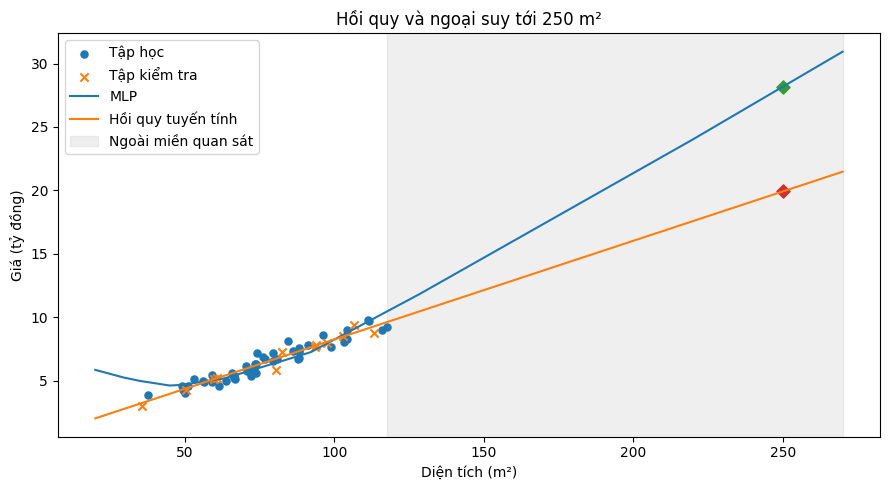

In [6]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "xor.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
df = pd.read_csv(tep_du_lieu("gia_nha.csv"))
# Dùng một đầu vào diện tích để so với bài 1 và dự đoán căn 250 m².
X, y = df[["dien_tich"]], df["gia"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
mang = make_pipeline(StandardScaler(), MLPRegressor(
    hidden_layer_sizes=(20,), max_iter=5000, random_state=0)).fit(X_tr, y_tr)
lr = LinearRegression().fit(X_tr, y_tr)
moi = pd.DataFrame({"dien_tich": [250.0]})
for ten, model in [("MLP", mang), ("Hồi quy tuyến tính", lr)]:
    print(f"{ten}: MAE kiểm tra = {mean_absolute_error(y_te, model.predict(X_te)):.6f} tỷ đồng; giá 250 m² = {model.predict(moi)[0]:.6f} tỷ đồng.")
print(f"Dữ liệu quan sát chỉ từ {X.dien_tich.min()} tới {X.dien_tich.max()} m².")
print("Căn 250 m² nằm ngoài dữ liệu; chưa có giá thật để khẳng định mô hình nào ngoại suy chính xác hơn. MLP ReLU là tuyến tính từng đoạn, độ dốc ngoài miền học phụ thuộc trọng số đã học; MAE tốt trong miền không bảo đảm ngoại suy tốt.")
print("Đường thẳng kéo dài xu hướng tuyến tính đã giả định, còn mạng có thể kéo dài theo độ dốc khác; cả hai dự đoán đều cần thận trọng khi dùng ngoài miền dữ liệu.")
luoi = pd.DataFrame({"dien_tich": np.linspace(20, 270, 400)})
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X_tr.dien_tich, y_tr, s=26, label="Tập học")
ax.scatter(X_te.dien_tich, y_te, s=35, marker="x", label="Tập kiểm tra")
for ten, model in [("MLP", mang), ("Hồi quy tuyến tính", lr)]:
    ax.plot(luoi.dien_tich, model.predict(luoi), label=ten)
    ax.scatter([250], model.predict(moi), marker="D", s=45)
ax.axvspan(X.dien_tich.max(), 270, color="gray", alpha=.12, label="Ngoài miền quan sát")
ax.set(xlabel="Diện tích (m²)", ylabel="Giá (tỷ đồng)", title="Hồi quy và ngoại suy tới 250 m²")
ax.legend()
fig.tight_layout()
plt.savefig(thu_muc_hinh / "hoi_quy_ngoai_suy.png", dpi=150)
plt.show()
